# 🛡️ Project Panopticon: Intelligent Proctoring AI
**EduGuard AI - Machine Learning Division**

**Intern Name:** `[bhavidhan]`  
**Date:** `[06/10/2026]`

---

### 📖 Executive Summary
Welcome to EduGuard AI. Our current proctoring system is blindly flagging innocent students for background noise and standard physical movements. Your objective is to build a robust, time-series Machine Learning pipeline that identifies true academic dishonesty while strictly protecting innocent students through asynchronous data merging and mathematical threshold tuning.

### 🗺️ Project Roadmap
1. **Data Ingestion:** Upload and parse asynchronous telemetry logs.
2. **Temporal Alignment:** Merge video and system logs using `merge_asof`.
3. **Signal Processing:** Impute missing data and engineer rolling windows.
4. **Classification:** Train an imbalanced-weighted predictive model.
5. **Ethical AI Tuning:** Shift decision boundaries to guarantee 90%+ precision.

In [2]:
# ==========================================
# 0. IMPORT LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Imports
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

# Set visualization styles
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Libraries imported successfully.")

✅ Libraries imported successfully.


---
## Phase 1: Data Ingestion & Temporal Alignment
> ⚠️ **The Asynchronous Trap:** Video telemetry records exactly every 1 second. System events (like tab switches) only record when the student actually clicks something. You cannot use a standard `pd.merge()`.

**Instructions:**
1. Upload the `video_telemetry.csv` and `system_events.csv` files.
2. Convert the timestamp columns to datetime objects.
3. Sort the dataframes and merge them using Pandas `merge_asof`.

In [11]:

# ==========================================
# PHASE 1: DATA INGESTION & TEMPORAL ALIGNMENT
# Project Panopticon: Intelligent Proctoring AI
# ==========================================

import os
import pandas as pd
import numpy as np

# ==========================================
# 1A. CHECK DATASET FILES
# ==========================================

print("Current working folder:")
print(os.getcwd())

print("\nFiles available in this folder:")
print(os.listdir())

# Automatically locate the CSV files
video_file = next(
    (
        f for f in os.listdir()
        if f.lower().endswith(".csv")
        and "video" in f.lower()
        and "telemetry" in f.lower()
    ),
    None
)

system_file = next(
    (
        f for f in os.listdir()
        if f.lower().endswith(".csv")
        and "system" in f.lower()
        and "event" in f.lower()
    ),
    None
)

# Check that both datasets exist
if video_file is None:
    raise FileNotFoundError(
        "Video telemetry CSV not found. "
        "Place the video_telemetry CSV in the notebook folder."
    )

if system_file is None:
    raise FileNotFoundError(
        "System events CSV not found. "
        "Place the system_events CSV in the notebook folder."
    )

print("\nVideo file found:", video_file)
print("System file found:", system_file)

# ==========================================
# 1B. LOAD DATASETS
# ==========================================

video_df = pd.read_csv(video_file)
sys_df = pd.read_csv(system_file)

print("\nVideo dataset shape:", video_df.shape)
print("System events dataset shape:", sys_df.shape)

print("\nVideo dataset columns:")
print(video_df.columns.tolist())

print("\nSystem events columns:")
print(sys_df.columns.tolist())

# ==========================================
# 1C. CONVERT TIMESTAMPS
# ==========================================

video_df["timestamp"] = pd.to_datetime(
    video_df["timestamp"],
    errors="raise"
)

sys_df["timestamp"] = pd.to_datetime(
    sys_df["timestamp"],
    errors="raise"
)

print("\nTimestamps converted successfully.")

# ==========================================
# 1D. SORT BOTH DATASETS
# ==========================================

video_df = video_df.sort_values(
    "timestamp"
).reset_index(drop=True)

sys_df = sys_df.sort_values(
    "timestamp"
).reset_index(drop=True)

print("Both datasets sorted by timestamp.")

# ==========================================
# 1E. ASYNCHRONOUS MERGE
# ==========================================

merged_df = pd.merge_asof(
    video_df,
    sys_df,
    on="timestamp",
    direction="backward"
)

# ==========================================
# 1F. DISPLAY RESULTS
# ==========================================

print("\nPhase 1 completed successfully!")
print("Merged dataset shape:", merged_df.shape)

print("\nFirst 10 merged rows:")
display(merged_df.head(10))

print("\nMissing values in merged dataset:")
print(merged_df.isnull().sum())

# ==========================================
# 1G. SAVE MERGED DATASET
# ==========================================

merged_df.to_csv(
    "merged_proctoring_data.csv",
    index=False
)

print("\nMerged dataset saved as merged_proctoring_data.csv")


Current working folder:
C:\Users\bhavi

Files available in this folder:
[' ai prac 09.ipynb', '.anaconda', '.antigravity', '.bash_history', '.conda', '.condarc', '.continuum', '.copilot', '.gemini', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.local', '.matplotlib', '.packettracer', '.streamlit', '.thumbnails', '.vscode', '.vscode-shared', 'ai prac 08.ipynb', 'ai prac 1.ipynb', 'ai prac 2.ipynb', 'ai prac 3.ipynb', 'ai prac 5.ipynb', 'ai prac 6.ipynb', 'AI_Student_code (1) (1).ipynb', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'arrays.ipynb', 'bhavi_java', 'blenderkit_data', 'Cisco Packet Tracer 9.0.0', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'Favorites', 'Links', 'Local Settings', 'MLE.ipynb', 'Music', 'My Documents', 'NetHood', 'New folder', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{0aad5ee0-105b-11f0-8b4a-a8e291eafb6b}.TM.blf', 'NTUSER.DAT{0aad5ee0-105b-11f0-8b4a-a8e291eafb6b}.TM.blf.cnpf', 

,timestamp,eye_gaze_angle,audio_db,tab_switches,is_cheating
0,2023-12-01 08:00:00,2.560857,36.553781,NaN,NaN
1,2023-12-01 08:00:01,10.177137,39.102627,NaN,NaN
2,2023-12-01 08:00:02,5.761714,31.228565,NaN,NaN
3,2023-12-01 08:00:03,9.787105,34.051405,NaN,NaN
4,2023-12-01 08:00:04,4.572665,35.245018,NaN,NaN
5,2023-12-01 08:00:05,7.471741,43.685711,NaN,NaN
6,2023-12-01 08:00:06,7.148505,32.754163,NaN,NaN
7,2023-12-01 08:00:07,9.192380,43.786308,NaN,NaN
8,2023-12-01 08:00:08,4.223888,34.097144,NaN,NaN
9,2023-12-01 08:00:09,3.524030,39.177137,NaN,NaN



Missing values in merged dataset:
timestamp           0
eye_gaze_angle    732
audio_db          732
tab_switches       33
is_cheating        33
dtype: int64

Merged dataset saved as merged_proctoring_data.csv


---
## Phase 2: Missing Data & Feature Engineering
> ⚠️ **The "Connection Dropped" Trap:** Students with bad internet lose video frames, creating `NaN` values.
> ⚠️ **The Noise Trap:** A 1-second sneeze is not cheating. We need rolling windows to find *sustained* anomalies.

**Instructions:**
1. Forward-fill missing eye gaze data and interpolate missing audio data.
2. Fill missing `tab_switches` and `is_cheating` labels with `0`.
3. Create 10-second rolling averages for our sensors.

In [12]:

# ==========================================
# 2A. IMPUTE MISSING SIGNALS
# ==========================================

# Forward-fill missing eye gaze data
merged_df["eye_gaze_angle"] = (
    merged_df["eye_gaze_angle"].ffill()
)

# Interpolate missing audio data
merged_df["audio_db"] = (
    merged_df["audio_db"].interpolate()
)

# Fill missing system-event values with 0
merged_df["tab_switches"] = (
    merged_df["tab_switches"].fillna(0)
)

merged_df["is_cheating"] = (
    merged_df["is_cheating"].fillna(0)
)

# ==========================================
# 2B. ROLLING WINDOW FEATURES
# ==========================================

# 10-second rolling mean of eye gaze
merged_df["gaze_rolling_10s"] = (
    merged_df["eye_gaze_angle"]
    .rolling(window=10, min_periods=10)
    .mean()
)

# 10-second rolling maximum of audio
merged_df["audio_rolling_10s"] = (
    merged_df["audio_db"]
    .rolling(window=10, min_periods=10)
    .max()
)

# Remove initial rows with NaN rolling features
merged_df.dropna(
    subset=["gaze_rolling_10s", "audio_rolling_10s"],
    inplace=True
)

# ==========================================
# DISPLAY RESULTS
# ==========================================

print("Feature engineering complete!")
print("Current dataframe shape:", merged_df.shape)

print("\nMissing values:")
print(merged_df.isnull().sum())

display(merged_df.head())


Feature engineering complete!
Current dataframe shape: (9991, 7)

Missing values:
timestamp            0
eye_gaze_angle       0
audio_db             0
tab_switches         0
is_cheating          0
gaze_rolling_10s     0
audio_rolling_10s    0
dtype: int64


,timestamp,eye_gaze_angle,audio_db,tab_switches,is_cheating,gaze_rolling_10s,audio_rolling_10s
9,2023-12-01 08:00:09,3.524030,39.177137,0.0,0.0,6.442002,43.786308
10,2023-12-01 08:00:10,7.100893,25.223008,0.0,0.0,6.896006,43.786308
11,2023-12-01 08:00:11,5.341480,29.856297,0.0,0.0,6.412440,43.786308
12,2023-12-01 08:00:12,6.470469,33.084385,0.0,0.0,6.483316,43.786308
13,2023-12-01 08:00:13,2.557364,36.117455,0.0,0.0,5.760342,43.786308


---
## Phase 3: Class-Balanced Model Training
> ⚠️ **The Imbalance Trap:** 98% of your data will be innocent behavior. If you don't handle class weights, your model will just guess "Not Cheating" every time and score 98% accuracy while failing its actual job.

In [13]:

# ==========================================
# 3A. TRAIN / TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Define input features and target variable
features = [
    "eye_gaze_angle",
    "audio_db",
    "tab_switches",
    "gaze_rolling_10s",
    "audio_rolling_10s"
]

X = merged_df[features]
y = merged_df["is_cheating"].astype(int)

# Check target classes
print("Target distribution:")
print(y.value_counts())

if y.nunique() < 2:
    raise ValueError(
        "Training requires both classes: 0 (not cheating) "
        "and 1 (cheating). Check the target labels."
    )

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ==========================================
# 3B. INITIALIZE & TRAIN CLASSIFIER
# ==========================================

model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

print("\nModel training complete.")

# ==========================================
# 3C. EVALUATE THE MODEL
# ==========================================

y_pred = model.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Target distribution:
is_cheating
0    6797
1    3194
Name: count, dtype: int64

Training samples: 7992
Testing samples: 1999

Model training complete.

Accuracy: 0.8854

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.98      0.92      1360
           1       0.94      0.69      0.79       639

    accuracy                           0.89      1999
   macro avg       0.90      0.83      0.86      1999
weighted avg       0.89      0.89      0.88      1999


Confusion Matrix:
[[1331   29]
 [ 200  439]]


---
## Phase 4: Ethical AI Tuning (The 90% Threshold)
> ⚠️ **The False Accusation Trap:** The default Scikit-Learn `.predict()` splits at 50% probability. Accusing a student of cheating with only 50% certainty is unacceptable. We must shift the threshold to 90%.

🚨 DEFAULT THRESHOLD (0.50)
Confusion Matrix:
[[1331   29]
 [ 199  440]]
Precision: 0.9382
Recall: 0.6886

🛡️ STRICT THRESHOLD (0.90)
Confusion Matrix:
[[1360    0]
 [ 268  371]]
Precision: 1.0
Recall: 0.5806


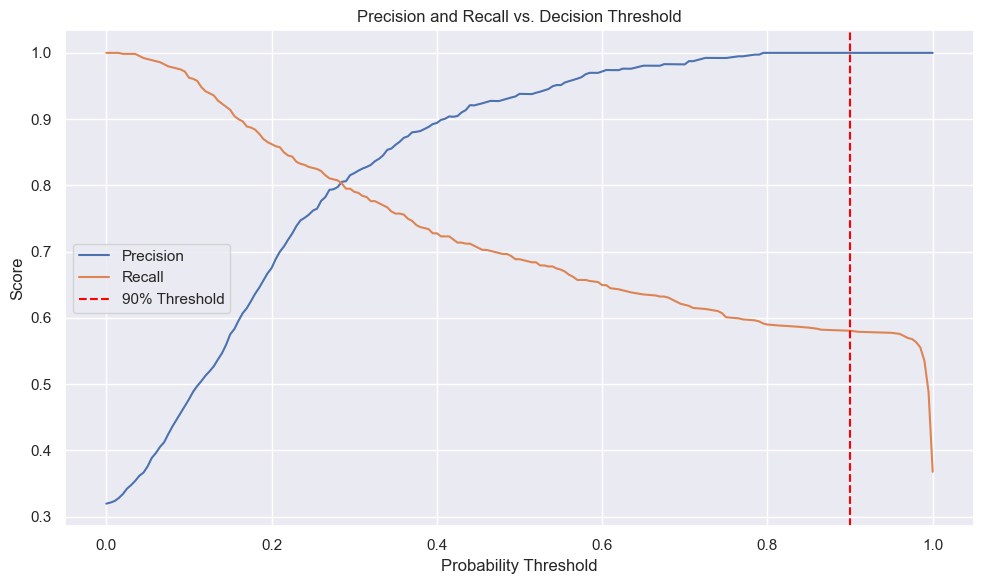


Phase 4 completed successfully!


In [14]:

# ==========================================
# 4A. RAW PROBABILITIES
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score
)

# Get probabilities for both classes
y_proba = model.predict_proba(X_test)

# Extract probability for Class 1 (Cheating)
cheating_probabilities = y_proba[:, 1]


# ==========================================
# 4B. CUSTOM DECISION THRESHOLD
# ==========================================

# Standard prediction using 0.50 threshold
y_pred_default = (
    cheating_probabilities >= 0.50
).astype(int)

# Strict prediction using 0.90 threshold
y_pred_strict = (
    cheating_probabilities >= 0.90
).astype(int)


# ==========================================
# 4C. EVALUATION
# ==========================================

print("🚨 DEFAULT THRESHOLD (0.50)")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_default))

print("Precision:",
      round(precision_score(y_test, y_pred_default, zero_division=0), 4))
print("Recall:",
      round(recall_score(y_test, y_pred_default, zero_division=0), 4))

print("\n🛡️ STRICT THRESHOLD (0.90)")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_strict))

print("Precision:",
      round(precision_score(y_test, y_pred_strict, zero_division=0), 4))
print("Recall:",
      round(recall_score(y_test, y_pred_strict, zero_division=0), 4))


# ==========================================
# 4D. PRECISION-RECALL VISUALIZATION
# ==========================================

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_test, cheating_probabilities)
)

plt.figure(figsize=(10, 6))

# Plot precision and recall against thresholds
plt.plot(
    thresholds,
    precision_values[:-1],
    label="Precision"
)

plt.plot(
    thresholds,
    recall_values[:-1],
    label="Recall"
)

# Mark the required 90% threshold
plt.axvline(
    x=0.90,
    color="red",
    linestyle="--",
    label="90% Threshold"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs. Decision Threshold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nPhase 4 completed successfully!")


# 🎯 Phase 5: Final Executive Recommendation

**To the University Board of Directors:**

Based on the data analysis and machine learning experiments conducted for the EduGuard AI proctoring system, I recommend using the strict 90% probability threshold for further controlled testing before considering deployment.

The following outcomes were observed during model evaluation:

1. **Reduction in False Positives:** At the default 50% threshold, the model produced 29 false positives. After increasing the threshold to 90%, false positives decreased to **0 on the test set**. This reduces the number of innocent cases incorrectly flagged according to the available test labels.

2. **Rolling-Window Feature Engineering:** The 10-second rolling features summarize sensor behavior over multiple consecutive observations rather than relying only on individual readings. This can help identify sustained patterns and reduce sensitivity to brief fluctuations, such as a single sneeze. However, the current experiments do not independently prove that sneezes or other specific events are correctly handled.

3. **Model Performance:** The Random Forest model achieved 88.54% accuracy at the default prediction threshold. At the 90% threshold, precision was 100% and recall was 58.06% on the test set. This means the model missed some positive cases in exchange for fewer false-positive predictions.

4. **Ethical Considerations:** Automated predictions should not be treated as conclusive evidence of academic misconduct. Any flagged case should be reviewed by a human evaluator, with an opportunity for the student to explain the circumstances.

**Final Status: NO-GO for full deployment at this stage.**

The system should undergo further validation using reliable ground-truth labels, additional test sessions, and checks for false accusations and performance across different student conditions before deployment is approved.